In [3]:
import ast
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print(sys.executable)  # should contain ".venv"

DATA = Path("data")
RESULTS = Path("results")
labels = pd.read_csv(DATA / "labeled_anomalies.csv")
labels.head()


/Users/huwwheeler/Documents/smap-msl-anomaly/.venv/bin/python3.11


,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505
1,S-1,SMAP,"[[5300, 5747]]",[point],7331
2,E-1,SMAP,"[[5000, 5030], [5610, 6086]]","[contextual, contextual]",8516
3,E-2,SMAP,"[[5598, 6995]]",[point],8532
4,E-3,SMAP,"[[5094, 8306]]",[point],8307


In [5]:
rows = []
for _, r in labels.iterrows():
    seqs = ast.literal_eval(r["anomaly_sequences"])
    classes = [c.strip().strip("'\"") for c in r["class"].strip("[]").split(",")]
    assert len(seqs) == len(classes), (r["chan_id"], seqs, classes)
    for (start, end), cls in zip(seqs, classes):
        rows.append({
            "chan_id": r["chan_id"],
            "spacecraft": r["spacecraft"],
            "class": cls,
            "start": start,
            "end": end,
            "length": end - start + 1,
            "num_values": r["num_values"],
        })
anoms = pd.DataFrame(rows)

print("anomaly sequences:", len(anoms))
print(anoms.groupby(["spacecraft", "class"]).size().unstack())
anoms.groupby("class")["length"].describe()


anomaly sequences: 105
class       contextual  point
spacecraft                   
MSL                 17     19
SMAP                26     43


,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
contextual,43.0,478.767442,882.313162,31.0,101.0,121.0,305.0,3865.0
point,62.0,713.258065,1108.446837,11.0,69.5,126.0,1001.0,4218.0


In [6]:
info = []
for chan in labels["chan_id"]:
    tr = np.load(DATA / "train" / f"{chan}.npy", mmap_mode="r")
    te = np.load(DATA / "test" / f"{chan}.npy", mmap_mode="r")
    info.append({"chan_id": chan, "train_len": tr.shape[0],
                 "test_len": te.shape[0], "n_features": tr.shape[1]})
info = pd.DataFrame(info).merge(
    labels[["chan_id", "spacecraft", "num_values"]], on="chan_id")
info["type"] = info["chan_id"].str[0]

print("test length matches labels file:", (info["test_len"] == info["num_values"]).all())
print(info.groupby("spacecraft")["n_features"].unique())
print(info.groupby("spacecraft")[["train_len", "test_len"]].agg(["min", "median", "max"]))
info.groupby(["spacecraft", "type"]).size().unstack(fill_value=0)

test length matches labels file: True
spacecraft
MSL     [55]
SMAP    [25]
Name: n_features, dtype: object
           train_len               test_len              
                 min  median   max      min  median   max
spacecraft                                               
MSL              439  2158.0  4308     1096  2277.0  6100
SMAP             312  2833.0  2881     4453  8302.0  8640


type,A,B,C,D,E,F,G,M,P,R,S,T
spacecraft,,,,,,,,,,,,
MSL,0,0,2,3,0,4,0,7,4,0,1,6
SMAP,9,1,0,12,13,3,6,0,8,1,1,3


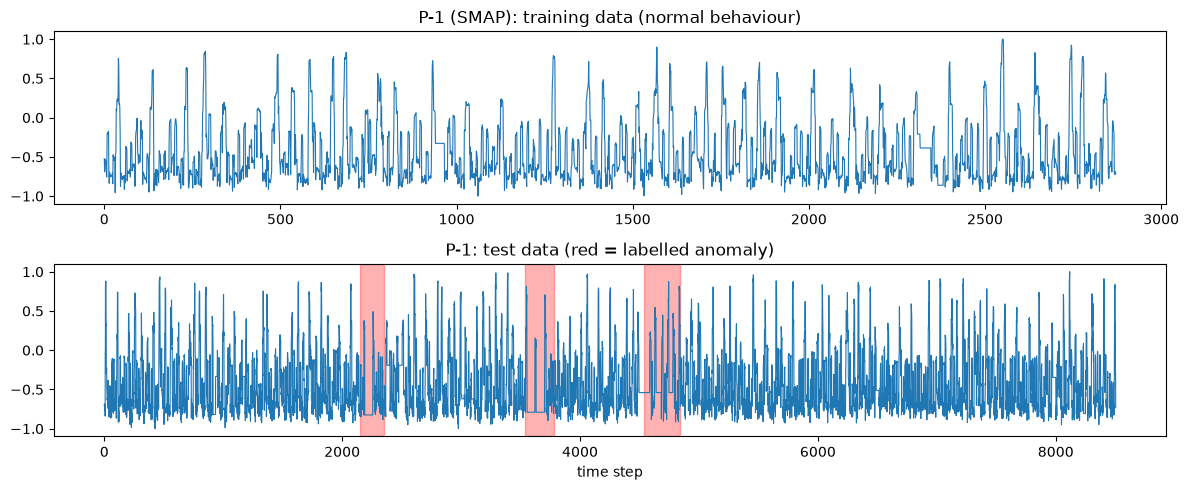

In [7]:
def plot_channel(chan, save=False):
    train = np.load(DATA / "train" / f"{chan}.npy")
    test = np.load(DATA / "test" / f"{chan}.npy")
    row = labels[labels["chan_id"] == chan].iloc[0]
    seqs = ast.literal_eval(row["anomaly_sequences"])

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharey=True)
    ax1.plot(train[:, 0], linewidth=0.8)
    ax1.set_title(f"{chan} ({row['spacecraft']}): training data (normal behaviour)")
    ax2.plot(test[:, 0], linewidth=0.8)
    for start, end in seqs:
        ax2.axvspan(start, end, color="red", alpha=0.3)
    ax2.set_title(f"{chan}: test data (red = labelled anomaly)")
    ax2.set_xlabel("time step")
    fig.tight_layout()
    if save:
        fig.savefig(RESULTS / f"channel_{chan}.png", dpi=150)
    plt.show()

plot_channel("P-1", save=True)

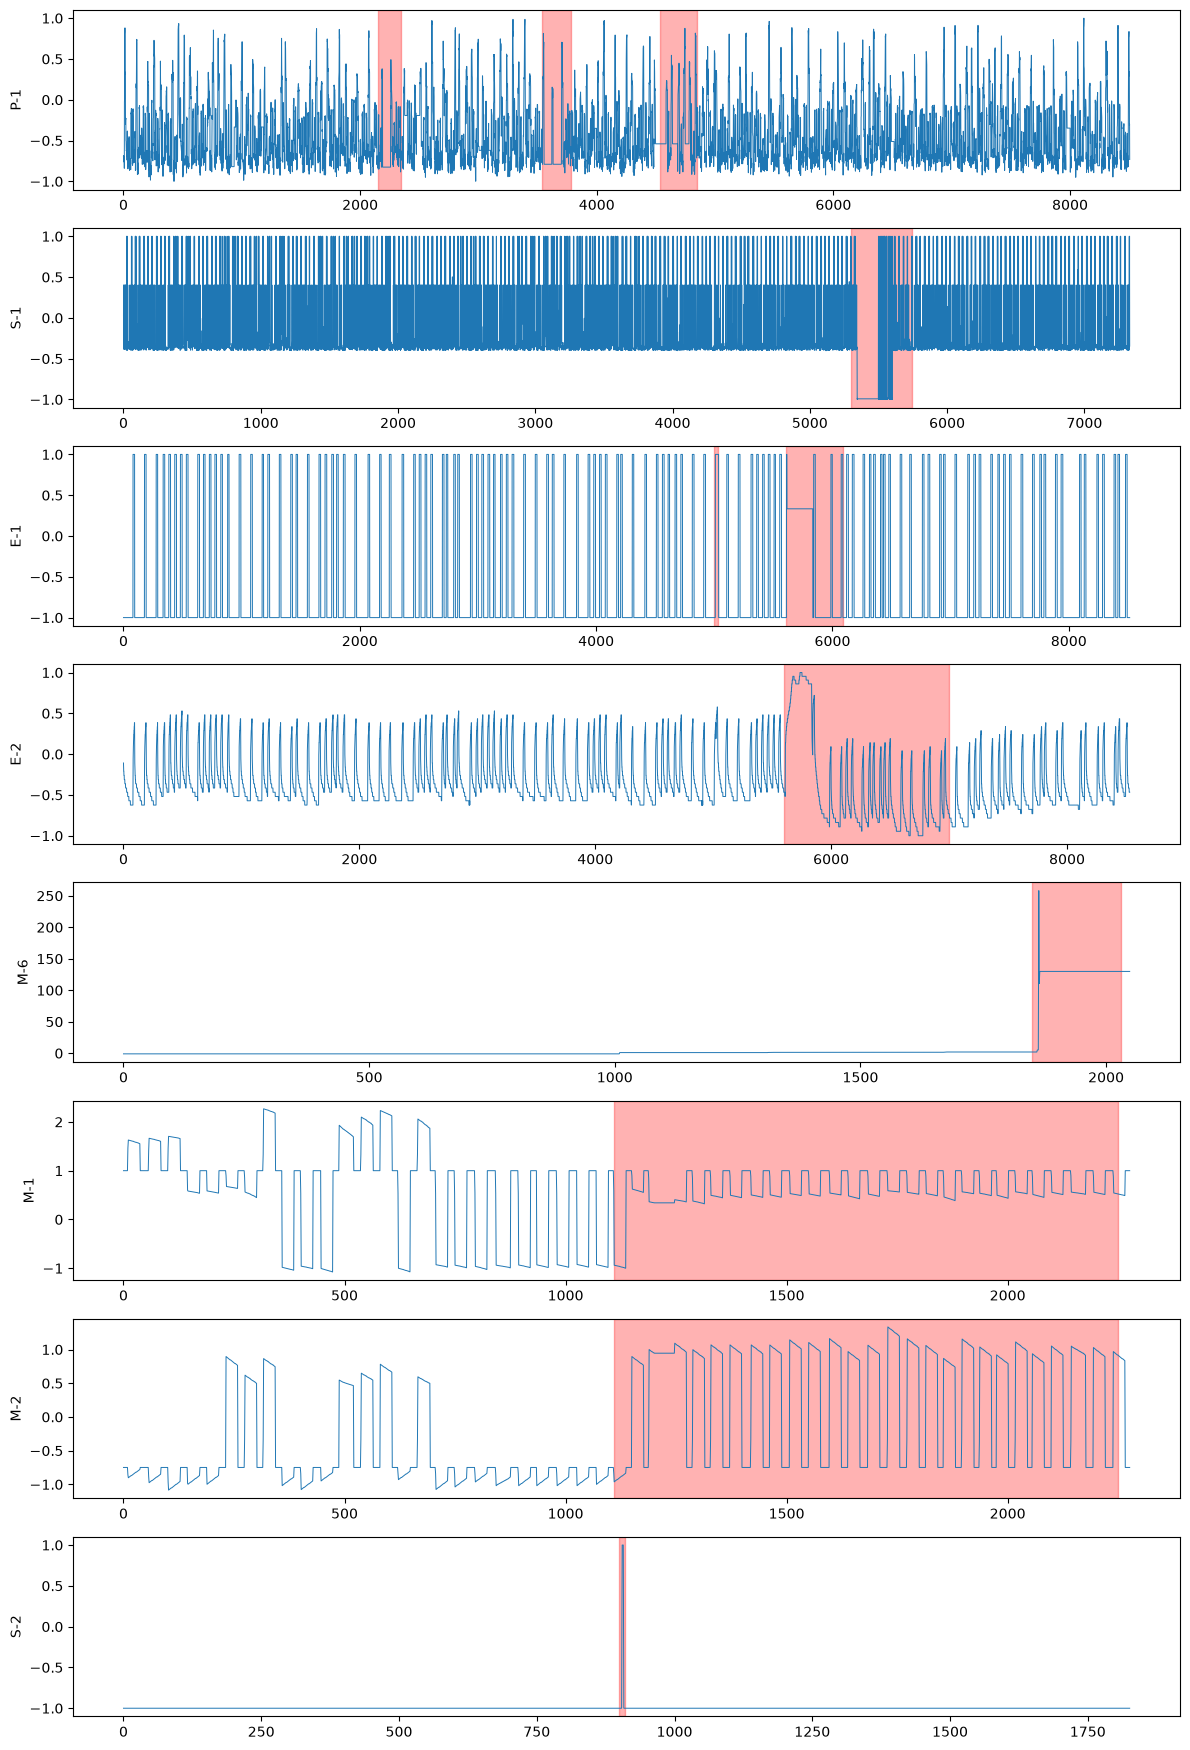

In [8]:
picks = labels.groupby("spacecraft").head(4)["chan_id"].tolist()
fig, axes = plt.subplots(len(picks), 1, figsize=(12, 2.2 * len(picks)))
for ax, chan in zip(axes, picks):
    test = np.load(DATA / "test" / f"{chan}.npy")
    seqs = ast.literal_eval(
        labels.loc[labels["chan_id"] == chan, "anomaly_sequences"].iloc[0])
    ax.plot(test[:, 0], linewidth=0.7)
    for start, end in seqs:
        ax.axvspan(start, end, color="red", alpha=0.3)
    ax.set_ylabel(chan)
fig.tight_layout()
fig.savefig(RESULTS / "channel_grid.png", dpi=150)
plt.show()

In [9]:
rng = []
for chan in labels["chan_id"]:
    tr = np.load(DATA / "train" / f"{chan}.npy", mmap_mode="r")[:, 0]
    te = np.load(DATA / "test" / f"{chan}.npy", mmap_mode="r")[:, 0]
    rng.append({"chan_id": chan, "train_min": tr.min(), "train_max": tr.max(),
                "test_min": te.min(), "test_max": te.max()})
rng = pd.DataFrame(rng)
outside = rng[(rng[["train_min", "test_min"]].min(axis=1) < -1.001)
              | (rng[["train_max", "test_max"]].max(axis=1) > 1.001)]
print(len(outside), "channels have values outside [-1, 1]")
outside

16 channels have values outside [-1, 1]


,chan_id,train_min,train_max,test_min,test_max
55,M-6,-1.000000,-1.000000,-1.000000,258.108108
56,M-1,-0.916094,2.492298,-1.076476,2.268854
57,M-2,-1.210726,0.886325,-1.084689,1.335276
59,P-10,0.985882,1.001129,-1.000000,1.000000
63,M-3,-1.477217,1.000071,-1.424197,1.000071
64,M-4,-1.465464,1.000005,-1.331441,1.175893
65,M-5,-1.255006,0.981588,-1.308986,1.095187
66,P-15,0.730839,1.005220,-1.000000,1.000000
67,C-1,-1.000000,2.193448,-1.000000,1.000000
71,F-4,-1.000000,0.754516,-1.000000,1.465473


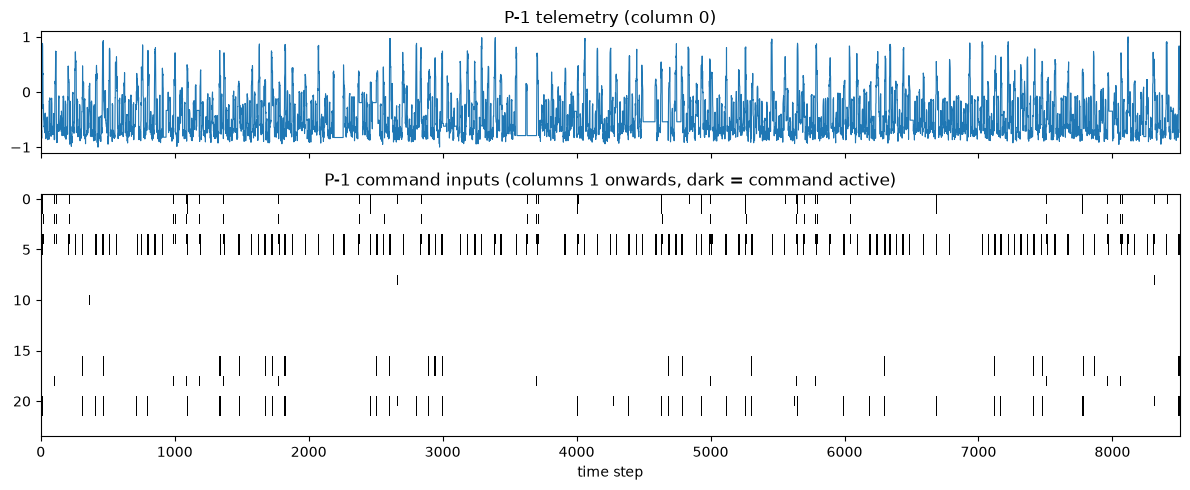

In [10]:
test = np.load(DATA / "test" / "P-1.npy")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True,
                               gridspec_kw={"height_ratios": [1, 2]})
ax1.plot(test[:, 0], linewidth=0.8)
ax1.set_title("P-1 telemetry (column 0)")
ax2.imshow(test[:, 1:].T, aspect="auto", interpolation="nearest", cmap="Greys")
ax2.set_title("P-1 command inputs (columns 1 onwards, dark = command active)")
ax2.set_xlabel("time step")
plt.tight_layout()
plt.show()

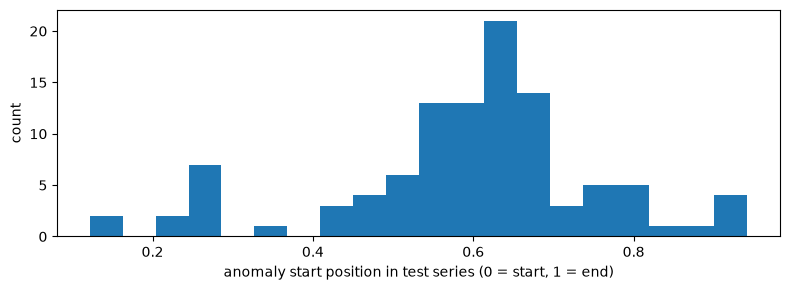

In [11]:
anoms["start_frac"] = anoms["start"] / anoms["num_values"]
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(anoms["start_frac"], bins=20)
ax.set_xlabel("anomaly start position in test series (0 = start, 1 = end)")
ax.set_ylabel("count")
fig.tight_layout()
fig.savefig(RESULTS / "anomaly_positions.png", dpi=150)
plt.show()

In [12]:
print(anoms["start_frac"].describe().round(2))
print("share starting between 55% and 72%:",
      round(anoms["start_frac"].between(0.55, 0.72).mean(), 2))
print("share starting in the first 10%:",
      round((anoms["start_frac"] < 0.10).mean(), 2))
print("share starting in the last 10%:",
      round((anoms["start_frac"] > 0.90).mean(), 2))

count    105.00
mean       0.59
std        0.16
min        0.12
25%        0.54
50%        0.61
75%        0.66
max        0.94
Name: start_frac, dtype: float64
share starting between 55% and 72%: 0.53
share starting in the first 10%: 0.0
share starting in the last 10%: 0.04


## Phase 1 findings

- 82 channels (55 SMAP, 27 MSL) and 105 labelled anomaly sequences: 43 contextual and 62 point.
- Anomalies vary hugely in length, from 11 to 4,218 steps (median 121 for contextual, 126 for point), so "point" anomalies are not single time steps.
- SMAP channels have 25 columns and MSL channels have 55: one telemetry value plus command inputs.
- SMAP training series are short next to the test series (median 2,833 vs 8,302 steps).
- 16 of 82 channels have values outside the documented -1 to 1 range, including all seven MSL "M" channels. M-6 reaches 258 in the test data.
- Anomalies start late in the test series: the median start is 61% of the way through, and 53% start between 55% and 72%. None start in the first 10% and 4% start in the last 10%.
- Some anomalies are obvious (e.g. M-6, S-1) and some are hard to see by eye (e.g. P-1, E-1).
- The channels look very different from one another: P-1 is dense and noisy, S-1 and E-1 switch between a few fixed levels, E-2, M-1 and M-2 are regular repeating waveforms, and M-6 and S-2 sit almost flat. A single detector has to cope with all of these.